# Measuring

You will build: a trail with a marker every kilometre, and a lake that knows which campsites are on its shore.

Run it from this folder with ``python measuring.py``, or open ``measuring.ipynb``.

In [1]:
import numpy as np

import svgwriter as svg

A winding trail and a lake.

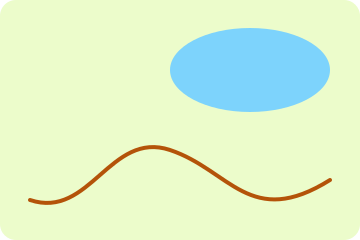

In [2]:
FONT = "Arial, Helvetica, sans-serif"
doc = svg.Document(360, 240)
doc.rect(0, 0, 360, 240, rx=16, fill="#ecfccb")
lake = doc.ellipse(250, 70, 80, 42, fill="#7dd3fc")
route = svg.PathBuilder().move_to(30, 200).curve_to(90, 220, 110, 130, 170, 150).smooth_curve_to(250, 230, 330, 180)
trail = doc.path(route, fill="none", stroke="#b45309", stroke_width=4, stroke_linecap="round")
doc

`total_length()` is how long the trail is, measured along its curves.

In [3]:
length = trail.total_length()
print(f"the trail is {length:.0f} units long")

the trail is 334 units long


`point_at_length(d)` finds the point `d` units along it. If 60 units is one kilometre, here are the markers.

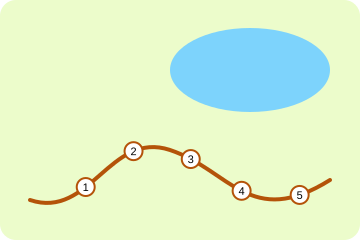

In [4]:
KM = 60
for km in range(1, int(length // KM) + 1):
    spot = trail.point_at_length(km * KM)
    doc.circle(spot.x, spot.y, 9, fill="white", stroke="#b45309", stroke_width=2)
    doc.text(str(km), x=spot.x, y=spot.y + 4, font_size=11, text_anchor="middle", font_family=FONT)
doc

`contains_point` checks points against a shape: campsites in the water turn grey, the rest green.

25 of 40 campsites are in the lake


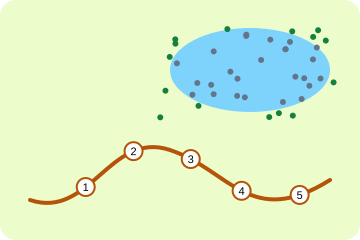

In [5]:
rng = np.random.default_rng(3)
camps = rng.uniform((160, 20), (340, 120), size=(40, 2))
wet = lake.contains_point(camps)
for (x, y), in_lake in zip(camps, wet, strict=True):
    doc.circle(x, y, 3, fill="#64748b" if in_lake else "#15803d")
print(f"{wet.sum()} of {len(camps)} campsites are in the lake")
doc

Save it. Next: [07 Typography](../07_typography/typography.py) styles text.

In [6]:
doc.save("06_measuring.svg")